# EDA 04 (khảo sát): độ phủ theo thứ và giờ

Dữ liệu có mặt vào những giờ nào, ngày nào, ở bao nhiêu user; Notebook không chọn trước khung giờ hay định nghĩa "qua đêm".

| Mục | Câu hỏi | Làm căn cứ cho |
|---|---|---|
| 1 | Dữ liệu phủ những giờ nào, ngày nào, ở bao nhiêu user? | Khung giờ home/office (A10), dữ liệu tối thiểu (A11) |

**Cách chạy.** Cần chạy một lần `python src/preprocess/convert_raw.py` trước (chuyển dữ liệu thô sang `data/interim`). Sau đó Run All; notebook nạp dữ liệu từ `data/interim` và tính trong khoảng 1–2 phút. Muốn chạy thử nhanh thì đặt `USERS_LIMIT` ở cell đầu. Trong cùng một phiên, chỉ sửa cell phân tích thì chỉ cần chạy lại cell đó.

Code tính toán nằm trong `src/eda/` (`scan.py`, `config.py`). Mục đánh số riêng trong từng notebook (bảng mục và notebook ở README).

**Quy ước.** Timestamp gốc là UTC (theo User Guide). "Giờ địa phương" theo giả thuyết ở `src/eda/config.py`, kiểm chứng ở notebook 03 mục 2. Một "bước" là cặp hai điểm liên tiếp của cùng user sau khi sắp xếp theo thời gian và bỏ timestamp trùng.

> **Giai đoạn: KHẢO SÁT (trước khi chia validation / test).** Chạy trên **toàn bộ 182 user**. Chỉ mô tả dữ liệu, **không chọn ngưỡng** ở đây. Ngưỡng chọn ở thư mục `notebooks/tuning/`, chỉ trên nhóm validation (D17).
>
> Các số trong ô văn bản bên dưới là của lần chạy cũ (bản chia 06/11); cập nhật sau khi chạy lại.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda.config import *          # dữ kiện từ tài liệu, mốc mô tả, bins (xem src/eda/config.py)
from eda.utils import pct, hist_quantile, qtable, fmt_s
from eda.scan import run
from eda import split

USERS_LIMIT = None   # khảo sát: toàn bộ user (chỉ mô tả, không chọn ngưỡng)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

R = run(topics=['coverage'], users=USERS_LIMIT)
users, files, A = R.users, R.files, R.A
gaps = R.gaps
print(f"{len(users)} user, {len(files):,} file")

[20/182] đã đọc tới user 019 (3 giây)


[40/182] đã đọc tới user 039 (5 giây)


[60/182] đã đọc tới user 059 (6 giây)


[80/182] đã đọc tới user 079 (7 giây)


[100/182] đã đọc tới user 099 (8 giây)


[120/182] đã đọc tới user 119 (9 giây)


[140/182] đã đọc tới user 139 (10 giây)


[160/182] đã đọc tới user 159 (12 giây)


[180/182] đã đọc tới user 179 (15 giây)
[182/182] đã đọc tới user 181 (15 giây)
182 user, 18,670 file


## 1. Độ phủ theo thứ và giờ

**Câu hỏi:** dữ liệu có mặt vào những giờ nào trong ngày, ngày nào trong tuần, và ở bao nhiêu user? Notebook không chọn trước khung giờ nào là "đêm" hay "giờ làm việc"; việc đó thuộc bước gán home/office.

**Đơn vị đo:** *phút có dữ liệu*, tức một phút (giờ địa phương) có ít nhất một điểm GPS. Cách này không cần ngưỡng khoảng trống, và không thiên về user ghi dày: user ghi mỗi giây hay mỗi 5 giây đều tính là 1 phút.

- `data_hours`: tổng số phút có dữ liệu của user, đổi ra giờ.
- `cov_wd_hour` (theo user): số phút có dữ liệu theo thứ × giờ.
- `days_hour` (theo user): số ngày khác nhau có dữ liệu trong mỗi giờ của ngày.


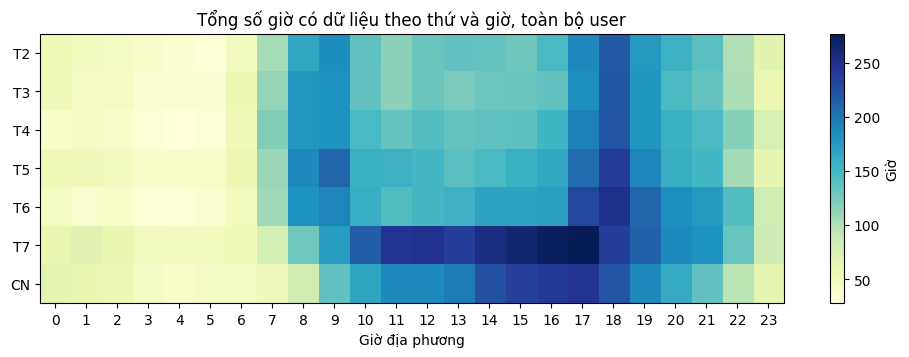

Tổng: 21,452 giờ có dữ liệu
  Thứ Hai đến thứ Sáu: 67.3%  |  Thứ Bảy, Chủ nhật: 32.7%


giờ,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
% số giờ có dữ liệu,1.8,1.7,1.6,1.3,1.2,1.3,1.7,3.2,5.1,5.9,5.2,5.1,5.3,5.2,5.6,5.7,6.0,7.1,7.5,6.2,5.4,5.0,3.7,2.3


In [2]:
cov = A["cov_wd_hour"].sum(axis=0) / 60      # giờ có dữ liệu, [thứ, giờ]
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(cov, aspect="auto", cmap="YlGnBu")
ax.set_yticks(range(7)); ax.set_yticklabels(WEEKDAYS)
ax.set_xticks(range(24)); ax.set_xlabel("Giờ địa phương")
ax.set_title("Tổng số giờ có dữ liệu theo thứ và giờ, toàn bộ user")
plt.colorbar(im, ax=ax, label="Giờ")
plt.show()
tot = cov.sum()
print(f"Tổng: {tot:,.0f} giờ có dữ liệu")
print(f"  Thứ Hai đến thứ Sáu: {cov[:5].sum() / tot * 100:.1f}%  |  Thứ Bảy, Chủ nhật: {cov[5:].sum() / tot * 100:.1f}%")
pd.Series(cov.sum(axis=0) / tot * 100, index=pd.Index(range(24), name="giờ"), name="% số giờ có dữ liệu").round(1).to_frame().T


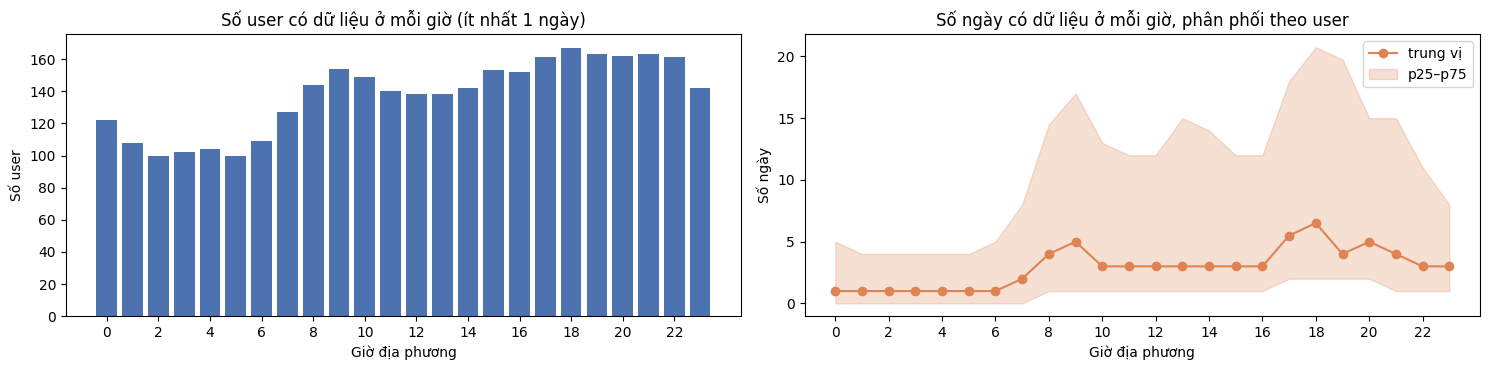

In [3]:
dh = A["days_hour"]          # [user, giờ]: số ngày có dữ liệu trong giờ đó
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].bar(range(24), (dh > 0).sum(axis=0), color="#4c72b0")
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xlabel("Giờ địa phương"); axes[0].set_ylabel("Số user")
axes[0].set_title("Số user có dữ liệu ở mỗi giờ (ít nhất 1 ngày)")
q = np.percentile(dh, [25, 50, 75], axis=0)
axes[1].plot(range(24), q[1], marker="o", color="#dd8452", label="trung vị")
axes[1].fill_between(range(24), q[0], q[2], color="#dd8452", alpha=0.25, label="p25–p75")
axes[1].set_xticks(range(0, 24, 2)); axes[1].set_xlabel("Giờ địa phương"); axes[1].set_ylabel("Số ngày")
axes[1].set_title("Số ngày có dữ liệu ở mỗi giờ, phân phối theo user")
axes[1].legend()
plt.tight_layout()
plt.show()


Số user có ít nhất *k* ngày có dữ liệu ở mỗi giờ địa phương. Các mức *k* chỉ là mốc mô tả; ngưỡng dữ liệu tối thiểu được chọn ở bước gán home/office.


In [4]:
levels = [1, 3, 5, 10, 20]
pd.DataFrame({f"≥ {k} ngày": (dh >= k).sum(axis=0) for k in levels},
             index=pd.Index(range(24), name="giờ")).T


giờ,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
≥ 1 ngày,122,108,100,102,104,100,109,127,144,154,149,140,138,138,142,153,152,161,167,163,162,163,161,142
≥ 3 ngày,72,64,57,58,58,58,63,85,111,116,102,96,103,98,97,103,112,119,128,115,120,108,108,93
≥ 5 ngày,47,45,45,40,38,41,51,74,89,93,80,79,77,76,73,75,81,94,105,90,92,89,84,73
≥ 10 ngày,33,28,29,22,16,21,25,40,63,64,55,51,57,57,56,55,56,69,76,75,64,60,52,41
≥ 20 ngày,16,12,11,6,5,8,14,26,40,43,37,34,36,33,32,32,33,43,48,46,36,32,32,25


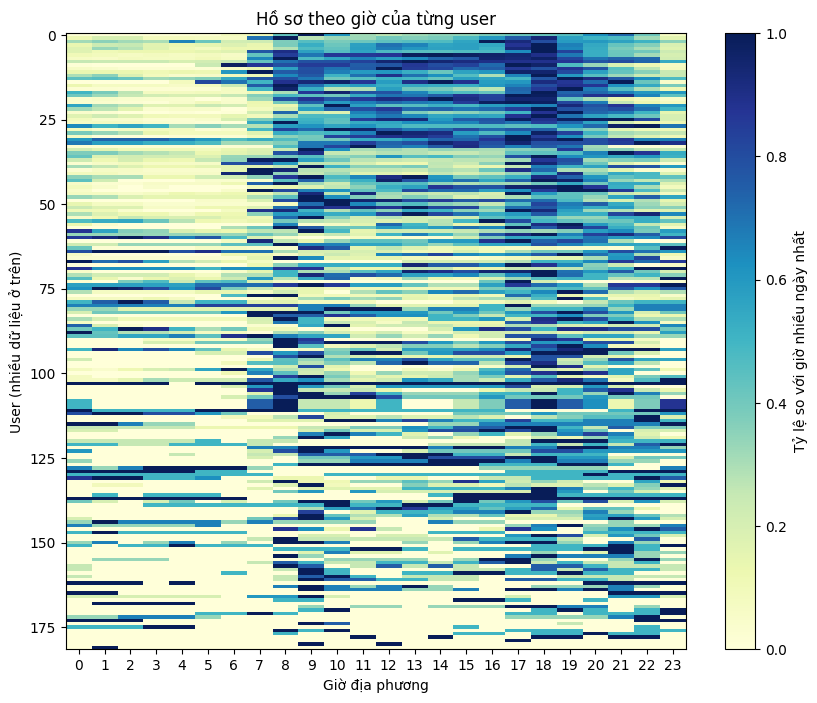

In [5]:
# Hồ sơ theo giờ của từng user: số ngày có dữ liệu ở mỗi giờ, chuẩn hóa theo giờ cao nhất của user đó
prof = dh / np.maximum(dh.max(axis=1, keepdims=True), 1)
order = np.argsort(-A["cov_wd_hour"].sum(axis=(1, 2)))
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(prof[order], aspect="auto", cmap="YlGnBu", interpolation="nearest")
ax.set_xticks(range(24)); ax.set_xlabel("Giờ địa phương")
ax.set_ylabel("User (nhiều dữ liệu ở trên)")
ax.set_title("Hồ sơ theo giờ của từng user")
plt.colorbar(im, ax=ax, label="Tỷ lệ so với giờ nhiều ngày nhất")
plt.show()


**Ngày thường và cuối tuần.** Cùng cách đo, tách riêng ngày thường (thứ Hai đến thứ Sáu) và cuối tuần (thứ Bảy, Chủ nhật), vì nhịp sinh hoạt hai loại ngày thường khác nhau. Số ngày cuối tuần chỉ bằng khoảng 2/5 số ngày thường, nên so sánh *hình dạng* theo giờ hơn là độ lớn.


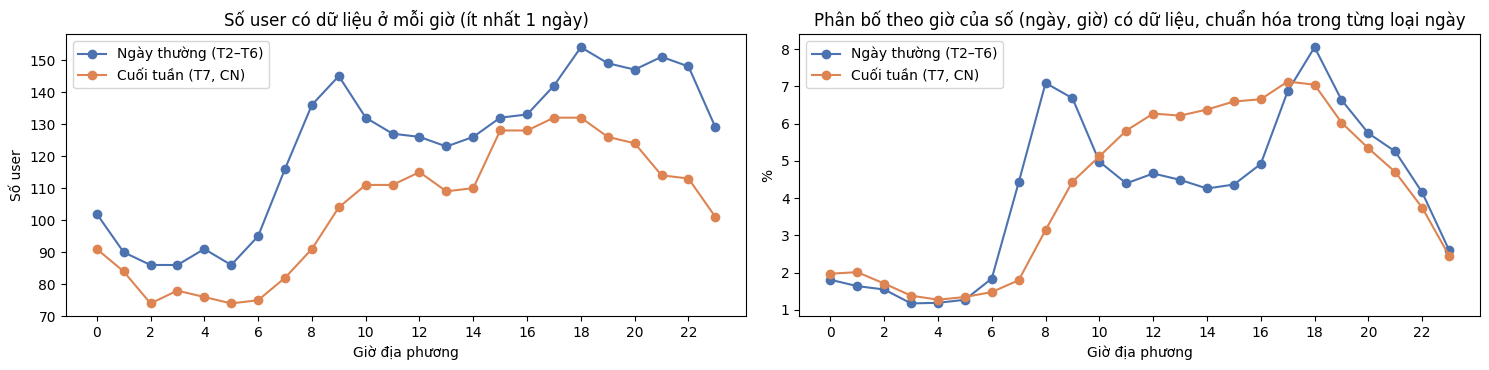

giờ                             0   1   2   3   4   5   6    7    8    9   \
Ngày thường (T2–T6) ≥ 1 ngày   102  90  86  86  91  86  95  116  136  145   
                    ≥ 3 ngày    60  53  48  45  41  46  52   77  105  103   
                    ≥ 5 ngày    40  33  35  29  29  31  34   59   79   85   
                    ≥ 10 ngày   21  18  18  13   8  13  20   32   52   59   
Cuối tuần (T7, CN)  ≥ 1 ngày    91  84  74  78  76  74  75   82   91  104   
                    ≥ 3 ngày    38  32  30  26  24  25  31   35   48   58   
                    ≥ 5 ngày    27  20  19  13  11  13  14   17   32   38   
                    ≥ 10 ngày    6   7   6   4   3   3   6    5   16   22   

giờ                             10   11   12   13   14   15   16   17   18  \
Ngày thường (T2–T6) ≥ 1 ngày   132  127  126  123  126  132  133  142  154   
                    ≥ 3 ngày    89   79   83   80   80   80   79  101  115   
                    ≥ 5 ngày    66   58   65   64   61   61   63   76   91   
                    ≥ 10 ngày   43   39   42   45   39   39   42   52   60   
Cuối tuần (T7, CN)  ≥ 1 ngày   111  111  115  109  110  128  128  132  132   
                    ≥ 3 ngày    60   65   68   68   70   67   73   81   79   
                    ≥ 5 ngày    46   44   49   56   54   49   53   60   59   
                    ≥ 10 ngày   27   28   27   27   26   30   30   30   31   

giờ                             19   20   21   22   23  
Ngày thường (T2–T6) ≥ 1 ngày   149  147  151  148  129  
                    ≥ 3 ngày   100  107   97   93   80  
                    ≥ 5 ngày    86   80   80   69   57  
                    ≥ 10 ngày   60   54   49   41   32  
Cuối tuần (T7, CN)  ≥ 1 ngày   126  124  114  113  101  
                    ≥ 3 ngày    75   69   57   56   43  
                    ≥ 5 ngày    55   46   39   40   30  
                    ≥ 10 ngày   25   26   24   16    9

In [6]:
dw = A["days_hour_wk"]        # [user, 0 = ngày thường / 1 = cuối tuần, giờ]
kinds = ["Ngày thường (T2–T6)", "Cuối tuần (T7, CN)"]
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for k, (lab, col) in enumerate(zip(kinds, ["#4c72b0", "#dd8452"])):
    axes[0].plot(range(24), (dw[:, k] > 0).sum(axis=0), marker="o", color=col, label=lab)
    share = dw[:, k].sum(axis=0) / max(dw[:, k].sum(), 1) * 100
    axes[1].plot(range(24), share, marker="o", color=col, label=lab)
axes[0].set_ylabel("Số user"); axes[0].set_title("Số user có dữ liệu ở mỗi giờ (ít nhất 1 ngày)")
axes[1].set_ylabel("%"); axes[1].set_title("Phân bố theo giờ của số (ngày, giờ) có dữ liệu, chuẩn hóa trong từng loại ngày")
for ax in axes:
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Giờ địa phương"); ax.legend()
plt.tight_layout()
plt.show()

levels = [1, 3, 5, 10]
pd.concat({lab: pd.DataFrame({f"≥ {k} ngày": (dw[:, j] >= k).sum(axis=0) for k in levels},
                             index=pd.Index(range(24), name="giờ")).T
           for j, lab in enumerate(kinds)})
